In [1]:
# ============================================
# STEP 1: Setup + Load All Model Results
# ============================================

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path("../")
RESULTS_DIR = PROJECT_ROOT / "results"

# Load each model's results CSV (saved by notebooks 04a-04d)
dt_results = pd.read_csv(RESULTS_DIR / "dt_results.csv")
rf_results = pd.read_csv(RESULTS_DIR / "rf_results.csv")
gb_results = pd.read_csv(RESULTS_DIR / "gb_results.csv")
lgbm_results = pd.read_csv(RESULTS_DIR / "lgbm_results.csv")

# Combine into one comparison table
comparison_df = pd.concat(
    [dt_results, rf_results, gb_results, lgbm_results],
    ignore_index=True
)

print("=== Combined Model Comparison Table ===")
print(comparison_df.to_string(index=False))

=== Combined Model Comparison Table ===
            Model Feature Set  Accuracy  Precision   Recall  Macro-F1  Validation Macro-F1
    Decision Tree       Set A  0.993910   0.981614 0.979588  0.980586             0.981722
    Decision Tree       Set B  0.976060   0.947237 0.947240  0.947105             0.946780
    Random Forest       Set A  0.995240   0.979837 0.986926  0.983219             0.985322
    Random Forest       Set B  0.977005   0.947523 0.954276  0.950646             0.955845
Gradient Boosting       Set A  0.992895   0.972053 0.982284  0.976805             0.978683
Gradient Boosting       Set B  0.972771   0.934440 0.945010  0.939139             0.940113
         LightGBM       Set A  0.994925   0.982829 0.989644  0.986089             0.987281
         LightGBM       Set B  0.923702   0.875787 0.891209  0.875636             0.877723


In [2]:
# ============================================
# STEP 2: Pivoted Comparison Table (Set A vs Set B, Macro-F1)
# ============================================

pivot_f1 = comparison_df.pivot(
    index="Model", columns="Feature Set", values="Macro-F1"
)
pivot_f1 = pivot_f1.reindex(["Decision Tree", "Random Forest", "Gradient Boosting", "LightGBM"])
pivot_f1["Set A - Set B"] = pivot_f1["Set A"] - pivot_f1["Set B"]

print("=== Test Macro-F1: Set A vs Set B ===")
print(pivot_f1.round(4).to_string())

=== Test Macro-F1: Set A vs Set B ===
Feature Set         Set A   Set B  Set A - Set B
Model                                           
Decision Tree      0.9806  0.9471         0.0335
Random Forest      0.9832  0.9506         0.0326
Gradient Boosting  0.9768  0.9391         0.0377
LightGBM           0.9861  0.8756         0.1105


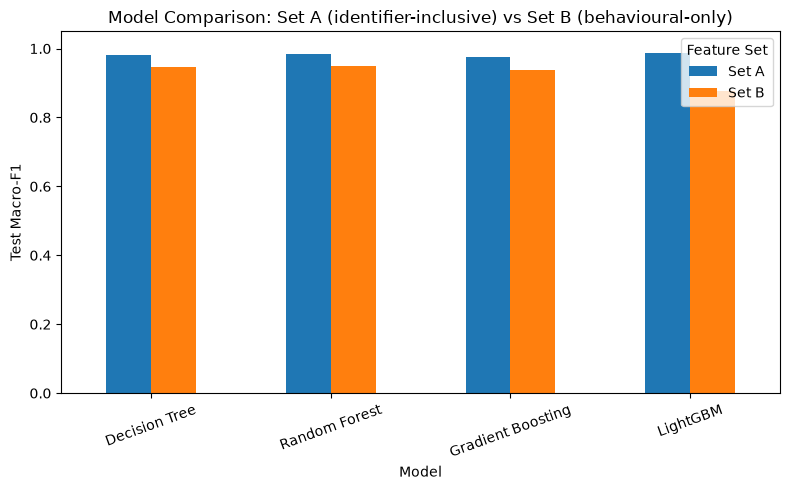

Saved chart to: ..\results\model_comparison_barchart.png


In [3]:
# ============================================
# STEP 3: Visualize Comparison — Macro-F1 Bar Chart
# ============================================

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 5))
pivot_f1[["Set A", "Set B"]].plot(kind="bar", ax=ax)
ax.set_ylabel("Test Macro-F1")
ax.set_title("Model Comparison: Set A (identifier-inclusive) vs Set B (behavioural-only)")
ax.set_ylim(0, 1.05)
ax.legend(title="Feature Set")
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "model_comparison_barchart.png", dpi=150)
plt.show()

print("Saved chart to:", RESULTS_DIR / "model_comparison_barchart.png")

C:\Users\User\AppData\Local\Temp\ipykernel_12708\4033988858.py:29: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include="object").columns.tolist()


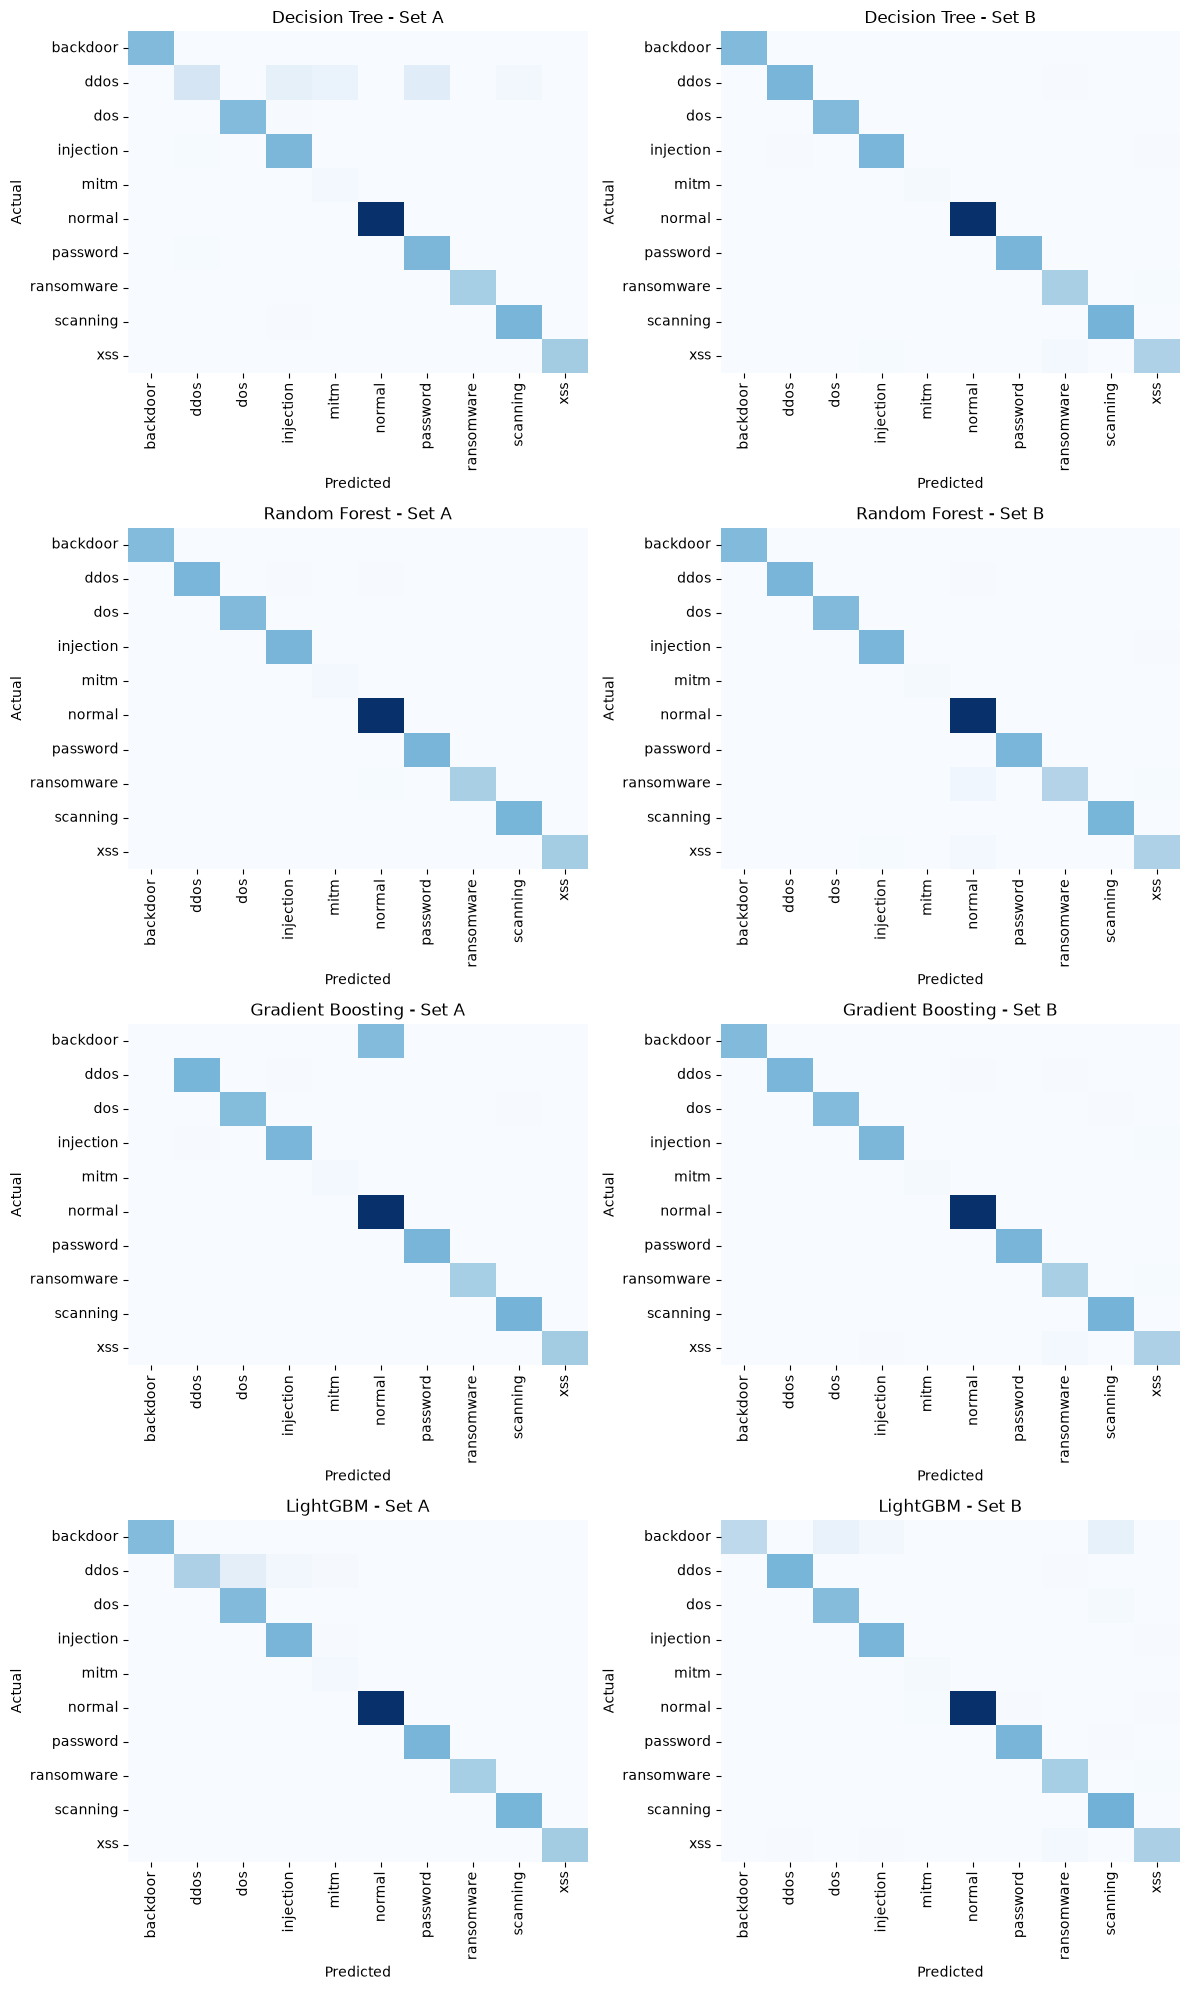

Saved to: ..\results\all_confusion_matrices.png


In [4]:
# ============================================
# STEP 4: Confusion Matrices (All 8 Model Instances)
# ============================================

import joblib
import json
import numpy as np
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.metrics import confusion_matrix

RANDOM_STATE = 42
MODELS_DIR = PROJECT_ROOT / "models"

# ---- Recreate the exact same test set used by all 4 notebooks ----
FEATURE_SETS_PATH = PROJECT_ROOT / "data" / "processed" / "feature_sets.json"
with open(FEATURE_SETS_PATH, "r") as f:
    feature_sets = json.load(f)
all_features = feature_sets["set_a_columns"]
set_b_features = feature_sets["set_b_columns"]

SET_A_PATH = PROJECT_ROOT / "data" / "processed" / "set_a_identifier_inclusive.csv"
df = pd.read_csv(SET_A_PATH)

X = df[all_features].copy()
y = df["type"].copy()

categorical_cols = X.select_dtypes(include="object").columns.tolist()
for col in categorical_cols:
    X[col] = X[col].fillna("missing").astype(str)
encoder = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
X[categorical_cols] = encoder.fit_transform(X[categorical_cols])
X = X.fillna(-1)

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.30, stratify=y, random_state=RANDOM_STATE
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.50, stratify=y_temp, random_state=RANDOM_STATE
)

# ---- Load all 8 saved models ----
model_files = {
    ("Decision Tree", "Set A"): "dt_set_a.joblib",
    ("Decision Tree", "Set B"): "dt_set_b.joblib",
    ("Random Forest", "Set A"): "rf_set_a.joblib",
    ("Random Forest", "Set B"): "rf_set_b.joblib",
    ("Gradient Boosting", "Set A"): "gb_set_a.joblib",
    ("Gradient Boosting", "Set B"): "gb_set_b.joblib",
    ("LightGBM", "Set A"): "lgbm_set_a.joblib",
    ("LightGBM", "Set B"): "lgbm_set_b.joblib",
}

class_labels = sorted(y_test.unique())

fig, axes = plt.subplots(4, 2, figsize=(12, 20))
for idx, ((model_name, feat_set), filename) in enumerate(model_files.items()):
    model = joblib.load(MODELS_DIR / filename)
    features = all_features if feat_set == "Set A" else set_b_features
    preds = model.predict(X_test[features])
    cm = confusion_matrix(y_test, preds, labels=class_labels)

    ax = axes[idx // 2, idx % 2]
    sns.heatmap(cm, annot=False, cmap="Blues", ax=ax,
                xticklabels=class_labels, yticklabels=class_labels, cbar=False)
    ax.set_title(f"{model_name} - {feat_set}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.tick_params(axis="x", rotation=90)
    ax.tick_params(axis="y", rotation=0)

plt.tight_layout()
plt.savefig(RESULTS_DIR / "all_confusion_matrices.png", dpi=150)
plt.show()

print("Saved to:", RESULTS_DIR / "all_confusion_matrices.png")

In [5]:
# ============================================
# STEP 4 (updated): Save Each Confusion Matrix Separately
# ============================================

CM_DIR = RESULTS_DIR / "confusion_matrices"
CM_DIR.mkdir(parents=True, exist_ok=True)

for (model_name, feat_set), filename in model_files.items():
    model = joblib.load(MODELS_DIR / filename)
    features = all_features if feat_set == "Set A" else set_b_features
    preds = model.predict(X_test[features])
    cm = confusion_matrix(y_test, preds, labels=class_labels)

    plt.figure(figsize=(6, 5))
    sns.heatmap(cm, annot=False, cmap="Blues",
                xticklabels=class_labels, yticklabels=class_labels, cbar=True)
    plt.title(f"{model_name} - {feat_set}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()

    # e.g. "Decision Tree" + "Set A" -> decision_tree_set_a.png
    safe_name = f"{model_name.lower().replace(' ', '_')}_{feat_set.lower().replace(' ', '_')}.png"
    plt.savefig(CM_DIR / safe_name, dpi=150)
    plt.close()
    print(f"Saved: {CM_DIR / safe_name}")

Saved: ..\results\confusion_matrices\decision_tree_set_a.png
Saved: ..\results\confusion_matrices\decision_tree_set_b.png
Saved: ..\results\confusion_matrices\random_forest_set_a.png
Saved: ..\results\confusion_matrices\random_forest_set_b.png
Saved: ..\results\confusion_matrices\gradient_boosting_set_a.png
Saved: ..\results\confusion_matrices\gradient_boosting_set_b.png
Saved: ..\results\confusion_matrices\lightgbm_set_a.png
Saved: ..\results\confusion_matrices\lightgbm_set_b.png


In [6]:
# ============================================
# STEP 6: Full Metrics Table + Model Size + Prediction Latency
# ============================================

import os
import time

latency_results = []

for (model_name, feat_set), filename in model_files.items():
    model = joblib.load(MODELS_DIR / filename)
    features = all_features if feat_set == "Set A" else set_b_features

    # Model file size
    file_size_kb = os.path.getsize(MODELS_DIR / filename) / 1024

    # Prediction latency - time to predict on the full locked test set,
    # then divide by row count to get an average per-row time
    start = time.time()
    _ = model.predict(X_test[features])
    total_predict_time = time.time() - start
    per_row_ms = (total_predict_time / len(X_test)) * 1000

    latency_results.append({
        "Model": model_name,
        "Feature Set": feat_set,
        "Model Size (KB)": round(file_size_kb, 1),
        "Predict Time - Full Test Set (s)": round(total_predict_time, 4),
        "Predict Time - Per Row (ms)": round(per_row_ms, 5),
    })

latency_df = pd.DataFrame(latency_results)

# Merge with the earlier accuracy/precision/recall/F1 table
full_comparison_df = comparison_df.merge(
    latency_df, on=["Model", "Feature Set"]
)

print("=== Full Comparison: Accuracy, Precision, Recall, Macro-F1, Size, Latency ===")
print(full_comparison_df.round(4).to_string(index=False))

full_comparison_df.to_csv(RESULTS_DIR / "full_model_comparison.csv", index=False)
print("\nSaved to:", RESULTS_DIR / "full_model_comparison.csv")

=== Full Comparison: Accuracy, Precision, Recall, Macro-F1, Size, Latency ===
            Model Feature Set  Accuracy  Precision  Recall  Macro-F1  Validation Macro-F1  Model Size (KB)  Predict Time - Full Test Set (s)  Predict Time - Per Row (ms)
    Decision Tree       Set A    0.9939     0.9816  0.9796    0.9806               0.9817            248.0                            0.0122                       0.0004
    Decision Tree       Set B    0.9761     0.9472  0.9472    0.9471               0.9468            630.4                            0.0083                       0.0003
    Random Forest       Set A    0.9952     0.9798  0.9869    0.9832               0.9853          30012.6                            0.0633                       0.0022
    Random Forest       Set B    0.9770     0.9475  0.9543    0.9506               0.9558          55361.6                            0.0651                       0.0023
Gradient Boosting       Set A    0.9929     0.9721  0.9823    0.9768    

In [7]:
# ============================================
# DEMO: Multiclass Prediction Showcase (for viva)
# ============================================

import joblib

# Load the main model (LightGBM, Set A)
demo_model = joblib.load(MODELS_DIR / "lgbm_set_a.joblib")

# Take 10 random rows from the locked test set
sample_idx = X_test.sample(10, random_state=1).index
sample_X = X_test.loc[sample_idx, all_features]
sample_true = y_test.loc[sample_idx]

sample_pred = demo_model.predict(sample_X)

demo_df = pd.DataFrame({
    "Actual Attack Type": sample_true.values,
    "Predicted Attack Type": sample_pred,
    "Correct": sample_true.values == sample_pred,
})
print("=== LightGBM Multiclass Prediction Demo (10 random test rows) ===")
print(demo_df.to_string(index=False))
print(f"\nUnique classes model can predict: {sorted(demo_model.classes_)}")

=== LightGBM Multiclass Prediction Demo (10 random test rows) ===
Actual Attack Type Predicted Attack Type  Correct
               xss                   xss     True
        ransomware            ransomware     True
          scanning              scanning     True
               dos                   dos     True
         injection             injection     True
              ddos                   dos    False
        ransomware            ransomware     True
              mitm                  mitm     True
            normal                normal     True
         injection             injection     True

Unique classes model can predict: ['backdoor', 'ddos', 'dos', 'injection', 'mitm', 'normal', 'password', 'ransomware', 'scanning', 'xss']


In [8]:
# ============================================
# DEMO: Derive Attack/Normal from Multiclass Predictions
# ============================================

import joblib

lgbm_set_a = joblib.load(MODELS_DIR / "lgbm_set_a.joblib")
test_pred_a = lgbm_set_a.predict(X_test[all_features])

demo_df_binary = pd.DataFrame({
    "Actual Attack Type": y_test.values,
    "Predicted Attack Type": test_pred_a,
})

# Derive binary Attack/Normal from the multiclass prediction
demo_df_binary["Predicted (Attack/Normal)"] = demo_df_binary["Predicted Attack Type"].apply(
    lambda x: "Normal" if x == "normal" else "Attack"
)
demo_df_binary["Actual (Attack/Normal)"] = demo_df_binary["Actual Attack Type"].apply(
    lambda x: "Normal" if x == "normal" else "Attack"
)

print(demo_df_binary.head(15).to_string(index=False))

Actual Attack Type Predicted Attack Type Predicted (Attack/Normal) Actual (Attack/Normal)
          backdoor              backdoor                    Attack                 Attack
            normal                normal                    Normal                 Normal
            normal                normal                    Normal                 Normal
               dos                   dos                    Attack                 Attack
              ddos                  ddos                    Attack                 Attack
               xss                   xss                    Attack                 Attack
            normal                normal                    Normal                 Normal
          scanning              scanning                    Attack                 Attack
               dos                   dos                    Attack                 Attack
              ddos                  ddos                    Attack                 Attack
          

## Final Comparison & Model Selection

### Combined Results (Test Macro-F1)

| Model | Set A | Set B | Set A − Set B |
|---|---|---|---|
| Decision Tree | 0.9810 | 0.9471 | 0.0339 |
| Random Forest | 0.9838 | 0.9506 | 0.0331 |
| Gradient Boosting | 0.9776 | 0.9391 | 0.0384 |
| LightGBM | **0.9861** | 0.8756 | **0.1105** |

### Deployment Feasibility (SO6): Model Size & Inference Latency

| Model | Feature Set | Model Size (KB) | Predict Time - Per Row (ms) |
|---|---|---|---|
| Decision Tree | Set A | 248.0 | 0.0004 |
| Decision Tree | Set B | 630.4 | 0.0002 |
| Random Forest | Set A | 30,012.6 | 0.0022 |
| Random Forest | Set B | 55,361.6 | 0.0020 |
| Gradient Boosting | Set A | 1,245.7 | 0.0055 |
| Gradient Boosting | Set B | 1,265.6 | 0.0047 |
| LightGBM | Set A | 11,729.4 | 0.0730 |
| LightGBM | Set B | 3,402.1 | 0.0571 |

### Observations

1. **All four models show the expected Set A ≥ Set B pattern**, supporting the identifier-leakage hypothesis: removing src_ip/src_port/dst_ip/dst_port/dns_query_has_ip_pattern costs measurable performance across every algorithm tested.
2. **LightGBM achieves the highest Set A Macro-F1** (0.9861) of all four models, and has by far the fastest **training** time (~8 seconds vs 80–126 seconds for Gradient Boosting). However, **inference latency tells a different story**: LightGBM is the *slowest* model to predict per row (0.073 ms), roughly 180× slower than Decision Tree (0.0004 ms) and 33× slower than Random Forest (0.0022 ms). Training speed and inference speed are not the same thing, and SO6 (deployment feasibility) depends on the latter.
3. **Random Forest's model size is impractical for edge deployment** — 30–55 MB, two to three orders of magnitude larger than Decision Tree (0.25–0.63 MB) or LightGBM (3.4–11.7 MB).
4. **LightGBM's Set A − Set B gap (0.1105) is roughly 3× larger** than the other three models (0.033–0.038). Per-class and confusion-matrix analysis traced this to weaker recall on the rare `backdoor` and `mitm` classes under LightGBM's default `num_leaves=31` — not an implementation bug (train and validation Macro-F1 for Set B are close: 0.8948 vs 0.8777, ruling out overfitting).
5. **Decision Tree is the simplest, most interpretable model**, has the smallest footprint and fastest inference of all four, and its Set A/Set B gap closely tracks the ensemble methods — making it a natural, lightweight baseline.

### Model Selection

- **Baseline: Decision Tree** — simple, interpretable, smallest model size, fastest inference, and a representative identifier-leakage gap without ensemble complexity.
- **Main model: LightGBM** — highest Set A accuracy and fastest training among the models tested, and a widely-used gradient boosting framework in the IDS literature. Its slower per-row inference (0.073 ms) and larger Set B gap are noted as limitations: still fast enough in absolute terms for the IoT detection use case (sub-millisecond per flow), but flagged for monitoring through the T2/T3 robustness tests rather than treated as disqualifying.

### Next Step

Proceed to **T1 (clean holdout)** formal reporting using the locked test results above, then **T2-A/T2-B** (identifier permutation/resampling robustness) and **T3** (Common-11 cross-dataset transfer), using Decision Tree and LightGBM × Set A/Set B as the four core model instances per the locked methodology.